<a href="https://colab.research.google.com/github/mariamhamdi917-stack/ML_projects/blob/main/laptop.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import re
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
from sklearn.model_selection import train_test_split, cross_val_score, KFold, RandomizedSearchCV
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.svm import SVR
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, ExtraTreesRegressor
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)
RANDOM_STATE = 42

In [ ]:
df = pd.read_csv("/content/laptopData(Target column Price).csv")

In [ ]:
print(df.shape)

(1303, 12)


In [ ]:
df.head()

,Unnamed: 0,Company,TypeName,Inches,ScreenResolution,Cpu,Ram,Memory,Gpu,OpSys,Weight,Price
0,0.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 2.3GHz,8GB,128GB SSD,Intel Iris Plus Graphics 640,macOS,1.37kg,71378.6832
1,1.0,Apple,Ultrabook,13.3,1440x900,Intel Core i5 1.8GHz,8GB,128GB Flash Storage,Intel HD Graphics 6000,macOS,1.34kg,47895.5232
2,2.0,HP,Notebook,15.6,Full HD 1920x1080,Intel Core i5 7200U 2.5GHz,NaN,256GB SSD,Intel HD Graphics 620,No OS,1.86kg,30636.0000
3,3.0,Apple,Ultrabook,15.4,IPS Panel Retina Display 2880x1800,Intel Core i7 2.7GHz,NaN,512GB SSD,AMD Radeon Pro 455,macOS,1.83kg,135195.3360
4,4.0,Apple,Ultrabook,13.3,IPS Panel Retina Display 2560x1600,Intel Core i5 3.1GHz,NaN,256GB SSD,Intel Iris Plus Graphics 650,macOS,1.37kg,96095.8080


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1303 entries, 0 to 1302
Data columns (total 12 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   Unnamed: 0        1246 non-null   float64
 1   Company           1238 non-null   object 
 2   TypeName          1183 non-null   object 
 3   Inches            1183 non-null   float64
 4   ScreenResolution  1118 non-null   object 
 5   Cpu               1070 non-null   object 
 6   Ram               1088 non-null   object 
 7   Memory            1104 non-null   object 
 8   Gpu               1149 non-null   object 
 9   OpSys             1193 non-null   object 
 10  Weight            1202 non-null   object 
 11  Price             1235 non-null   float64
dtypes: float64(3), object(9)
memory usage: 122.3+ KB


In [ ]:
print(df.isnull().sum())
print((df.isnull().mean() * 100).round(2))
print(df.duplicated().sum())
print(df.drop(columns="Unnamed: 0").isnull().all(axis=1).sum())

Unnamed: 0           57
Company              65
TypeName            120
Inches              120
ScreenResolution    185
Cpu                 233
Ram                 215
Memory              199
Gpu                 154
OpSys               110
Weight              101
Price                68
dtype: int64
Unnamed: 0           4.37
Company              4.99
TypeName             9.21
Inches               9.21
ScreenResolution    14.20
Cpu                 17.88
Ram                 16.50
Memory              15.27
Gpu                 11.82
OpSys                8.44
Weight               7.75
Price                5.22
dtype: float64
49
58


In [ ]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Unnamed: 0,1246.0,NaN,NaN,NaN,660.506421,376.558891,0.0,341.25,666.0,986.75,1302.0
Company,1238,19,Lenovo,283,NaN,NaN,NaN,NaN,NaN,NaN,NaN
TypeName,1183,6,Notebook,664,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Inches,1183.0,NaN,NaN,NaN,15.09738,1.859457,10.1,14.0,15.6,15.6,35.6
ScreenResolution,1118,39,Full HD 1920x1080,436,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Cpu,1070,111,Intel Core i5 7200U 2.5GHz,153,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Ram,1088,10,8GB,507,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Memory,1104,39,256GB SSD,344,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gpu,1149,106,Intel HD Graphics 620,251,NaN,NaN,NaN,NaN,NaN,NaN,NaN
OpSys,1193,9,Windows 10,984,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [ ]:
for c in df.select_dtypes(exclude="number").columns:
    print(c, df[c].nunique())

Company 19
TypeName 6
ScreenResolution 39
Cpu 111
Ram 10
Memory 39
Gpu 106
OpSys 9
Weight 183


In [ ]:
df = df.drop(columns="Unnamed: 0")
df = df.dropna(how="all")
df = df.drop_duplicates()
df = df.dropna(subset=["Price"]).reset_index(drop=True)

df["Ram"] = pd.to_numeric(df["Ram"].str.replace("GB", "", regex=False), errors="coerce")
df["Weight"] = pd.to_numeric(df["Weight"].str.replace("kg", "", regex=False), errors="coerce")

print(sorted(df.loc[df["Inches"] > 20, "Inches"].unique()))
df.loc[df["Inches"] > 20, "Inches"] = (df.loc[df["Inches"] > 20, "Inches"] / 2.54).round(1)

print(df.shape)

[np.float64(24.0), np.float64(25.6), np.float64(31.6), np.float64(33.5), np.float64(35.6)]
(1206, 11)


In [ ]:
df["Touchscreen"] = df["ScreenResolution"].str.contains("Touchscreen", na=False).astype(int)
df["IPS"] = df["ScreenResolution"].str.contains("IPS", na=False).astype(int)
res = df["ScreenResolution"].str.extract(r"(\d{3,4})x(\d{3,4})").astype(float)
df["X_res"], df["Y_res"] = res[0], res[1]
df["PPI"] = (np.sqrt(df["X_res"] ** 2 + df["Y_res"] ** 2) / df["Inches"]).round(2)

def cpu_brand(x):
    if pd.isna(x):
        return np.nan
    if x.startswith("Intel Core i7"): return "Intel Core i7"
    if x.startswith("Intel Core i5"): return "Intel Core i5"
    if x.startswith("Intel Core i3"): return "Intel Core i3"
    if x.startswith("Intel"):         return "Other Intel"
    return "AMD"

df["Cpu_brand"] = df["Cpu"].apply(cpu_brand)
df["Cpu_GHz"] = pd.to_numeric(df["Cpu"].str.extract(r"(\d+\.?\d*)\s*GHz")[0], errors="coerce")

def parse_memory(s):
    out = {"SSD_GB": 0.0, "HDD_GB": 0.0, "Flash_GB": 0.0, "Hybrid_GB": 0.0}
    if pd.isna(s):
        return pd.Series({k: np.nan for k in out})
    for part in s.split("+"):
        m = re.match(r"\s*(\d+\.?\d*)\s*(TB|GB)\s*(.*)", part)
        if not m:
            continue
        size = float(m.group(1)) * (1000 if m.group(2) == "TB" else 1)
        kind = m.group(3).upper()
        if "SSD" in kind:      out["SSD_GB"] += size
        elif "HDD" in kind:    out["HDD_GB"] += size
        elif "FLASH" in kind:  out["Flash_GB"] += size
        elif "HYBRID" in kind: out["Hybrid_GB"] += size
    return pd.Series(out)

df = pd.concat([df, df["Memory"].apply(parse_memory)], axis=1)

df["Gpu_brand"] = df["Gpu"].str.split().str[0]

def os_group(x):
    if pd.isna(x): return np.nan
    if "Windows" in x: return "Windows"
    if x in ("macOS", "Mac OS X"): return "Mac"
    if x == "Linux": return "Linux"
    return "Other/No OS"

df["OS"] = df["OpSys"].apply(os_group)

df = df.drop(columns=["ScreenResolution", "Cpu", "Memory", "Gpu", "OpSys"])
df.head()

,Company,TypeName,Inches,Ram,Weight,Price,Touchscreen,IPS,X_res,Y_res,PPI,Cpu_brand,Cpu_GHz,SSD_GB,HDD_GB,Flash_GB,Hybrid_GB,Gpu_brand,OS
0,Apple,Ultrabook,13.3,8.0,1.37,71378.6832,0,1,2560.0,1600.0,226.98,Intel Core i5,2.3,128.0,0.0,0.0,0.0,Intel,Mac
1,Apple,Ultrabook,13.3,8.0,1.34,47895.5232,0,0,1440.0,900.0,127.68,Intel Core i5,1.8,0.0,0.0,128.0,0.0,Intel,Mac
2,HP,Notebook,15.6,NaN,1.86,30636.0000,0,0,1920.0,1080.0,141.21,Intel Core i5,2.5,256.0,0.0,0.0,0.0,Intel,Other/No OS
3,Apple,Ultrabook,15.4,NaN,1.83,135195.3360,0,1,2880.0,1800.0,220.53,Intel Core i7,2.7,512.0,0.0,0.0,0.0,AMD,Mac
4,Apple,Ultrabook,13.3,NaN,1.37,96095.8080,0,1,2560.0,1600.0,226.98,Intel Core i5,3.1,256.0,0.0,0.0,0.0,Intel,Mac


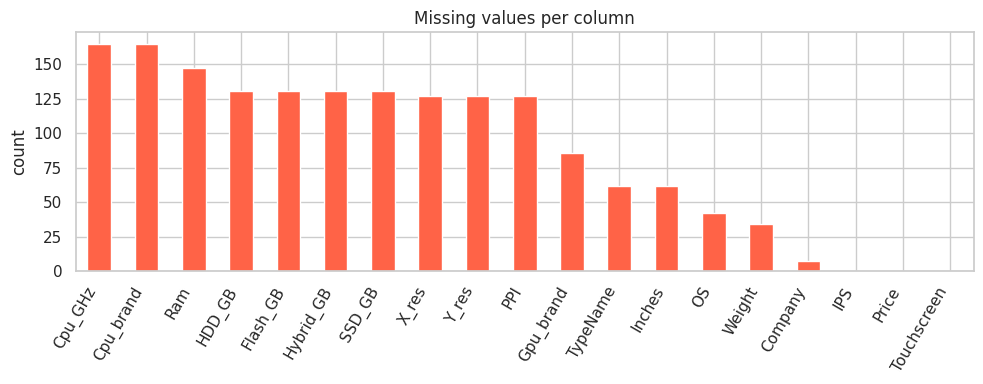

In [ ]:
plt.figure(figsize=(10, 4))
df.isnull().sum().sort_values(ascending=False).plot(kind="bar", color="tomato")
plt.title("Missing values per column")
plt.ylabel("count")
plt.xticks(rotation=60, ha="right")
plt.tight_layout()
plt.show()

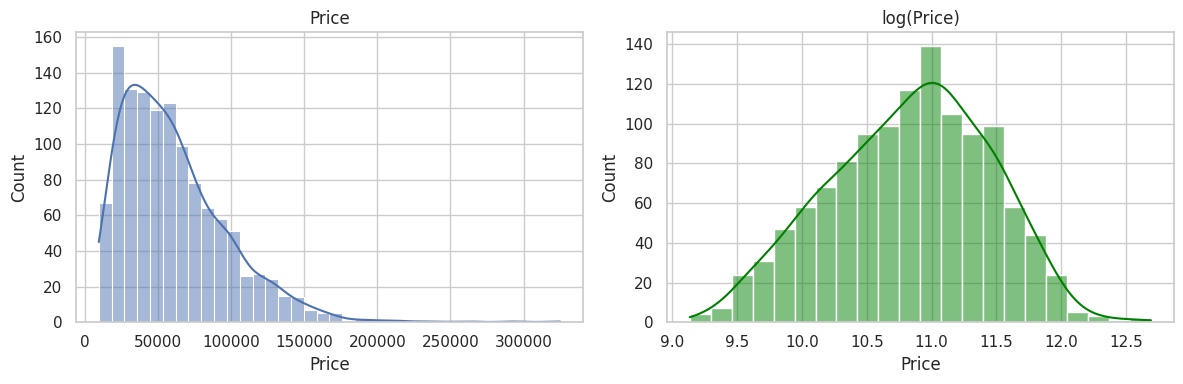

1.52 -0.18


In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Price"], kde=True, ax=ax[0])
ax[0].set_title("Price")
sns.histplot(np.log1p(df["Price"]), kde=True, ax=ax[1], color="green")
ax[1].set_title("log(Price)")
plt.tight_layout()
plt.show()
print(round(df["Price"].skew(), 2), round(np.log1p(df["Price"]).skew(), 2))

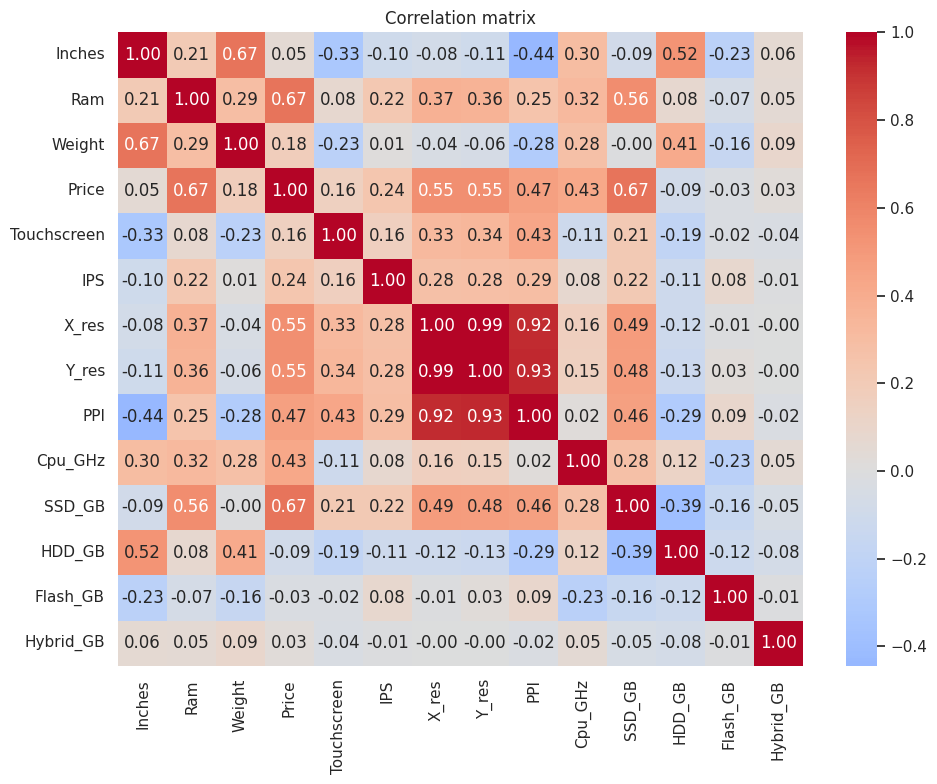

In [ ]:
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes("number").corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation matrix")
plt.tight_layout()
plt.show()

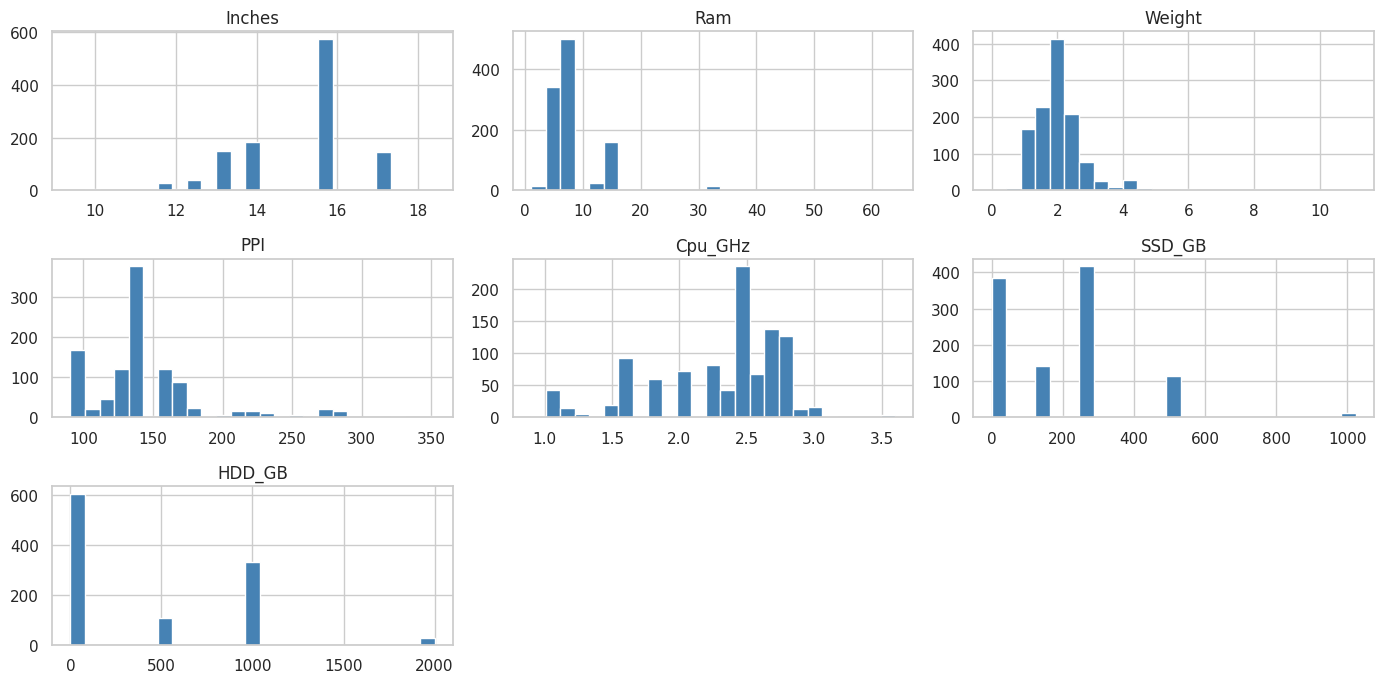

In [ ]:
num_plot = ["Inches", "Ram", "Weight", "PPI", "Cpu_GHz", "SSD_GB", "HDD_GB"]
df[num_plot].hist(bins=25, figsize=(14, 7), color="steelblue")
plt.tight_layout()
plt.show()

In [ ]:
X = df.drop(columns="Price")
y = df["Price"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)
print(X_train.shape, X_test.shape)

(964, 18) (242, 18)


In [ ]:
num_cols = X_train.select_dtypes(include="number").columns.tolist()
cat_cols = [c for c in X_train.columns if c not in num_cols]
print(num_cols)
print(cat_cols)

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])
cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=5, sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
])

['Inches', 'Ram', 'Weight', 'Touchscreen', 'IPS', 'X_res', 'Y_res', 'PPI', 'Cpu_GHz', 'SSD_GB', 'HDD_GB', 'Flash_GB', 'Hybrid_GB']
['Company', 'TypeName', 'Cpu_brand', 'Gpu_brand', 'OS']


In [ ]:
def make_pipeline(model):
    return Pipeline([
        ("prep", preprocessor),
        ("model", TransformedTargetRegressor(regressor=model, func=np.log1p, inverse_func=np.expm1)),
    ])

models = {
    "Linear Regression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001, max_iter=10000),
    "KNN": KNeighborsRegressor(n_neighbors=5),
    "SVR": SVR(C=10),
    "Decision Tree": DecisionTreeRegressor(max_depth=10, random_state=RANDOM_STATE),
    "Random Forest": RandomForestRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Extra Trees": ExtraTreesRegressor(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}

kf = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
rows, fitted = [], {}
for name, m in models.items():
    pipe = make_pipeline(m).fit(X_train, y_train)
    fitted[name] = pipe
    pred_tr, pred_te = pipe.predict(X_train), pipe.predict(X_test)
    cv = cross_val_score(make_pipeline(m), X_train, y_train, cv=kf, scoring="r2")
    rows.append({
        "Model": name,
        "Train R2": r2_score(y_train, pred_tr),
        "CV R2 (mean)": cv.mean(),
        "Test R2": r2_score(y_test, pred_te),
        "Test MAE": mean_absolute_error(y_test, pred_te),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, pred_te)),
    })

results = pd.DataFrame(rows).sort_values("Test R2", ascending=False).reset_index(drop=True)
results.round(3)

,Model,Train R2,CV R2 (mean),Test R2,Test MAE,Test RMSE
0,Gradient Boosting,0.837,0.686,0.713,12150.189,19197.847
1,Random Forest,0.945,0.704,0.669,12506.341,20608.421
2,SVR,0.932,0.660,0.632,13597.652,21728.421
3,Extra Trees,0.997,0.667,0.595,12684.678,22793.576
4,KNN,0.770,0.636,0.567,15405.400,23572.866
5,Decision Tree,0.889,0.553,0.558,15266.036,23815.213
6,Linear Regression,0.617,0.494,0.490,16471.249,25557.565
7,Ridge,0.618,0.511,0.485,16529.573,25687.549
8,Lasso,0.615,0.519,0.477,16575.293,25886.738


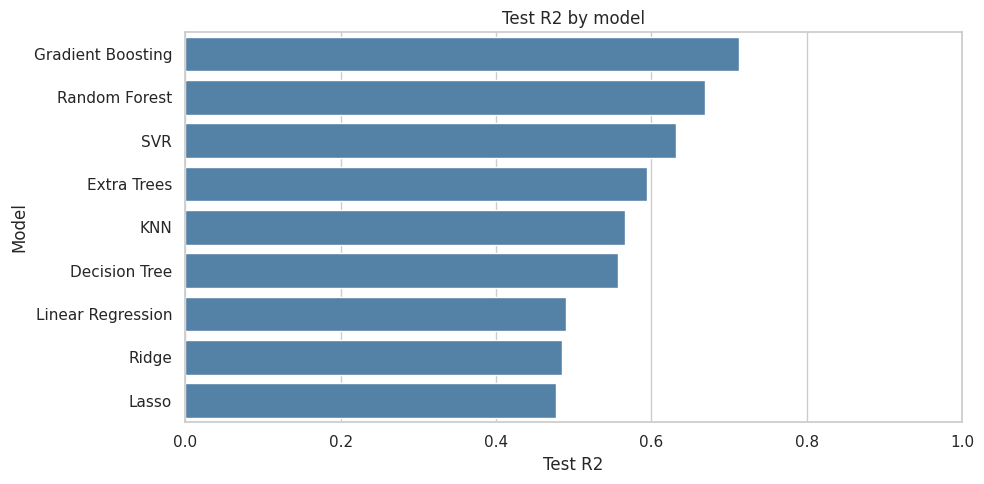

In [ ]:
plt.figure(figsize=(10, 5))
sns.barplot(data=results, y="Model", x="Test R2", color="steelblue")
plt.xlim(0, 1)
plt.title("Test R2 by model")
plt.tight_layout()
plt.show()

In [ ]:
param_rf = {
    "model__regressor__n_estimators": [200, 300, 500],
    "model__regressor__max_depth": [None, 10, 15, 20],
    "model__regressor__min_samples_split": [2, 5, 10],
    "model__regressor__min_samples_leaf": [1, 2, 4],
    "model__regressor__max_features": ["sqrt", 0.5, 1.0],
}
param_gb = {
    "model__regressor__n_estimators": [200, 300, 500],
    "model__regressor__learning_rate": [0.02, 0.05, 0.1],
    "model__regressor__max_depth": [2, 3, 4, 5],
    "model__regressor__subsample": [0.7, 0.85, 1.0],
    "model__regressor__min_samples_leaf": [1, 3, 5],
}

searches = {}
for name, base, grid in [
    ("Random Forest (tuned)", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1), param_rf),
    ("Gradient Boosting (tuned)", GradientBoostingRegressor(random_state=RANDOM_STATE), param_gb),
]:
    rs = RandomizedSearchCV(make_pipeline(base), grid, n_iter=20, cv=kf, scoring="r2",
                            random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
    searches[name] = rs
    print(name, round(rs.best_score_, 3))
    print({k.replace("model__regressor__", ""): v for k, v in rs.best_params_.items()})

Random Forest (tuned) 0.725
{'n_estimators': 500, 'min_samples_split': 2, 'min_samples_leaf': 1, 'max_features': 'sqrt', 'max_depth': 15}
Gradient Boosting (tuned) 0.733
{'subsample': 0.7, 'n_estimators': 500, 'min_samples_leaf': 5, 'max_depth': 4, 'learning_rate': 0.05}


In [ ]:
final_rows = []
for name, rs in searches.items():
    p = rs.best_estimator_.predict(X_test)
    final_rows.append({
        "Model": name,
        "Test R2": r2_score(y_test, p),
        "Test MAE": mean_absolute_error(y_test, p),
        "Test RMSE": np.sqrt(mean_squared_error(y_test, p)),
    })

final = pd.concat([results[["Model", "Test R2", "Test MAE", "Test RMSE"]], pd.DataFrame(final_rows)])
final = final.sort_values("Test R2", ascending=False).reset_index(drop=True)
print(final.round(3))

best_name = max(searches, key=lambda k: r2_score(y_test, searches[k].best_estimator_.predict(X_test)))
best_model = searches[best_name].best_estimator_
y_pred = best_model.predict(X_test)
print(best_name)

                        Model  Test R2   Test MAE  Test RMSE
0   Gradient Boosting (tuned)    0.721  11509.895  18920.108
1           Gradient Boosting    0.713  12150.189  19197.847
2               Random Forest    0.669  12506.341  20608.421
3       Random Forest (tuned)    0.656  12359.471  20986.786
4                         SVR    0.632  13597.652  21728.421
5                 Extra Trees    0.595  12684.678  22793.576
6                         KNN    0.567  15405.400  23572.866
7               Decision Tree    0.558  15266.036  23815.213
8           Linear Regression    0.490  16471.249  25557.565
9                       Ridge    0.485  16529.573  25687.549
10                      Lasso    0.477  16575.293  25886.738
Gradient Boosting (tuned)


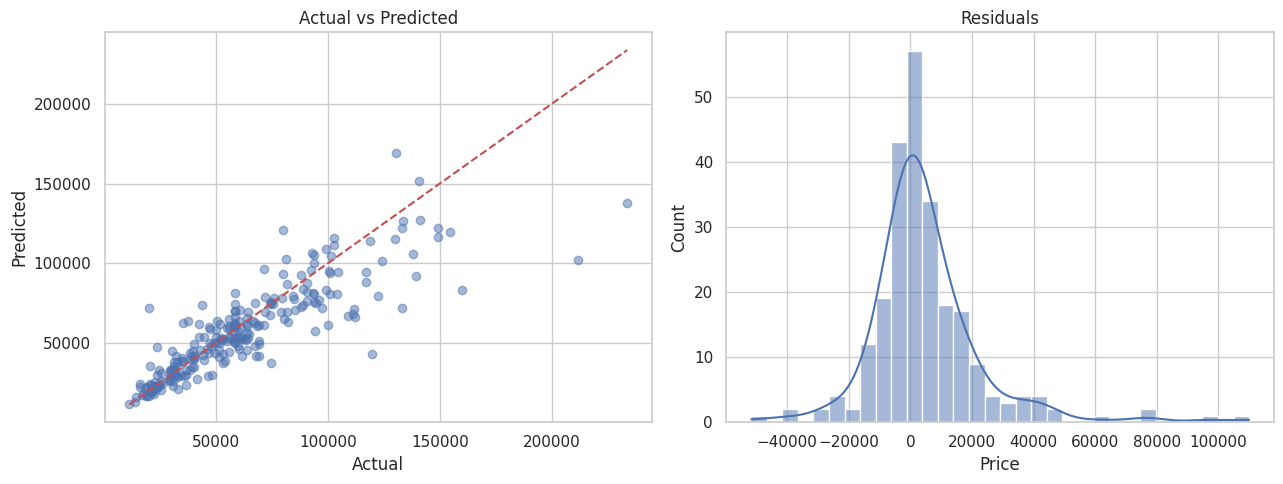

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
ax[0].scatter(y_test, y_pred, alpha=0.5)
lims = [y_test.min(), y_test.max()]
ax[0].plot(lims, lims, "r--")
ax[0].set_xlabel("Actual")
ax[0].set_ylabel("Predicted")
ax[0].set_title("Actual vs Predicted")
sns.histplot(y_test - y_pred, kde=True, ax=ax[1])
ax[1].set_title("Residuals")
plt.tight_layout()
plt.show()

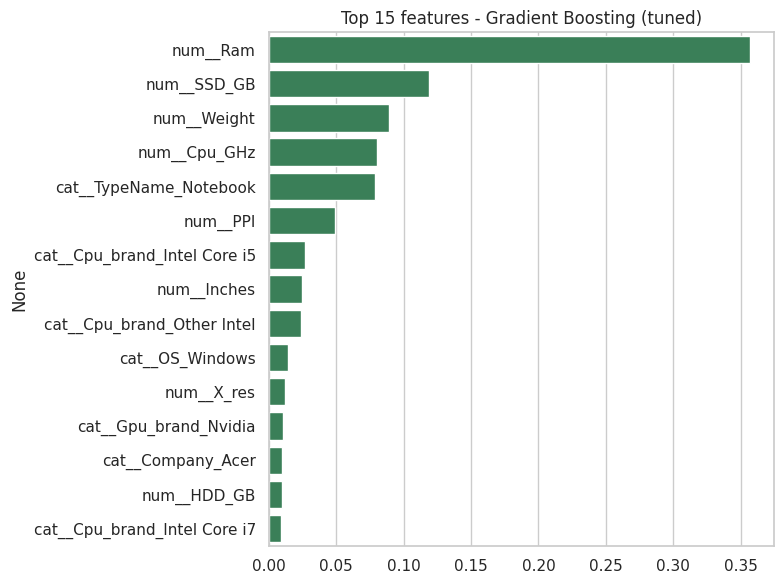

In [ ]:
feat_names = best_model.named_steps["prep"].get_feature_names_out()
imp = best_model.named_steps["model"].regressor_.feature_importances_
imp_s = pd.Series(imp, index=feat_names).sort_values(ascending=False).head(15)

plt.figure(figsize=(8, 6))
sns.barplot(x=imp_s.values, y=imp_s.index, color="seagreen")
plt.title(f"Top 15 features - {best_name}")
plt.tight_layout()
plt.show()

In [ ]:
joblib.dump(best_model, "laptop_price_model.joblib")

loaded = joblib.load("laptop_price_model.joblib")
sample = X_test.iloc[[0]]
print(sample.T)
print(round(float(loaded.predict(sample)[0])), round(float(y_test.iloc[0])))

                   101
Company      Microsoft
TypeName     Ultrabook
Inches            13.5
Ram                NaN
Weight           1.252
Touchscreen          1
IPS                  0
X_res           2256.0
Y_res           1504.0
PPI             200.84
Cpu_brand          NaN
Cpu_GHz            NaN
SSD_GB           256.0
HDD_GB             0.0
Flash_GB           0.0
Hybrid_GB          0.0
Gpu_brand        Intel
OS             Windows
96205 71395
